In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch, time
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")
big = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-3B-Instruct", torch_dtype=torch.float16).cuda()
small = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", torch_dtype=torch.float16).cuda()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [2]:
text = tok.apply_chat_template([{"role": "user", "content": "Explain how a car engine works."}],
                               add_generation_prompt=True, tokenize=False)
enc = tok(text, return_tensors="pt").to("cuda")

def run(assistant=None):
    big.generate(**enc, max_new_tokens=20, do_sample=False, assistant_model=assistant)  # warm-up
    torch.cuda.synchronize(); t = time.time()
    out = big.generate(**enc, max_new_tokens=200, do_sample=False, assistant_model=assistant)
    torch.cuda.synchronize()
    n = out.shape[1] - enc["input_ids"].shape[1]
    return n / (time.time() - t), out

normal_tps, out1 = run()
spec_tps, out2 = run(small)
print(f"Normal: {normal_tps:.1f} tok/s | Speculative: {spec_tps:.1f} tok/s | Speed-up: {spec_tps/normal_tps:.2f}x")
print("Same output:", torch.equal(out1, out2))

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'min_new_tokens', 'use_cache'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] A custom logits processor of type <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> to see related `.generate()` flags.


Normal: 20.9 tok/s | Speculative: 12.9 tok/s | Speed-up: 0.62x
Same output: True


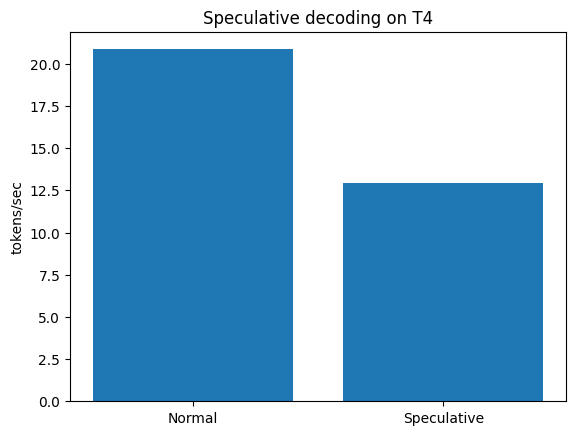

In [3]:
import matplotlib.pyplot as plt
plt.bar(["Normal", "Speculative"], [normal_tps, spec_tps])
plt.ylabel("tokens/sec"); plt.title("Speculative decoding on T4"); plt.show()

In [3]:
!pip install -q vllm
!pip show vllm | head -2

Name: vllm
Version: 0.33.0
ERROR: Pipe to stdout was broken


In [4]:
!pip show vllm

Name: vllm
Version: 0.33.0
Summary: A high-throughput and memory-efficient inference and serving engine for LLMs
Home-page: https://github.com/vllm-project/vllm
Author: vLLM Team
Author-email: 
License-Expression: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: aiohttp, anthropic, apache-tvm-ffi, blake3, cachetools, cbor2, certifi, cloudpickle, compressed-tensors, depyf, einops, fastapi, fastsafetensors, filelock, flashinfer-python, huggingface_hub, humming-kernels, ijson, instanttensor, jsonschema, lark, llguidance, lm-format-enforcer, mcp, mistral_common, model-hosting-container-standards, msgspec, multidict, ninja, numba, numpy, nvidia-cudnn-frontend, nvidia-cutlass-dsl, nvtx, openai, opencv-python-headless, opentelemetry-api, opentelemetry-exporter-otlp, opentelemetry-sdk, opentelemetry-semantic-conventions-ai, orjson, oss-harmony, outlines_core, partial-json-parser, pillow, prometheus-fastapi-instrumentator, prometheus_client, protobuf, psutil, py-cpuinfo, p

In [5]:
import time
from vllm import LLM, SamplingParams

prompt = "Explain how a car engine works."
params = SamplingParams(max_tokens=200, temperature=0)

llm = LLM(model="Qwen/Qwen2.5-3B-Instruct", dtype="half",
          gpu_memory_utilization=0.8, max_model_len=2048)
llm.generate([prompt], params)          # warm-up
t = time.time()
out = llm.generate([prompt], params)
n = len(out[0].outputs[0].token_ids)
print(f"NORMAL: {n/(time.time()-t):.1f} tok/s")

W1115 02:31:16.692000 50 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1115 02:31:16.693000 50 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1115 02:31:16.695000 50 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=50) INFO 11-15 02:31:37 [startup.py:96] non-default args: {'dtype': 'half', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

(MainProcess pid=50) INFO 11-15 02:31:55 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=50) WARNING 11-15 02:31:55 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=50) INFO 11-15 02:31:55 [model.py:2170] Using max model len 2048
(MainProcess pid=50) INFO 11-15 02:31:55 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

... (13 outputs left out)

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.42s/it, est. speed input: 1.48 toks/s, output: 36.90 toks/s]


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.41s/it, est. speed input: 1.48 toks/s, output: 36.97 toks/s]

NORMAL: 36.9 tok/s


In [ ]:
import os
os._exit(0)

In [1]:
#SPECULATIVE: 26.2 tok/s

In [2]:
import time
from vllm import LLM, SamplingParams

prompt = "Explain how a car engine works."
params = SamplingParams(max_tokens=200, temperature=0)

llm = LLM(model="Qwen/Qwen2.5-3B-Instruct", dtype="half",
          gpu_memory_utilization=0.8, max_model_len=2048,
          speculative_config={"model": "Qwen/Qwen2.5-0.5B-Instruct",
                              "num_speculative_tokens": 2})
llm.generate([prompt], params)          # warm-up
t = time.time()
out = llm.generate([prompt], params)
n = len(out[0].outputs[0].token_ids)
print(f"SPECULATIVE: {n/(time.time()-t):.1f} tok/s")

W1115 02:46:45.732000 2221 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1115 02:46:45.734000 2221 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1115 02:46:45.735000 2221 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=2221) INFO 11-15 02:46:56 [startup.py:96] non-default args: {'dtype': 'half', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'speculative_config': {'model': 'Qwen/Qwen2.5-0.5B-Instruct', 'num_speculative_tokens': 2}, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=2221) INFO 11-15 02:46:57 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=2221) WARNING 11-15 02:46:57 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=2221) INFO 11-15 02:46:57 [model.py:2170] Using max model len 2048
(MainProcess pid=2221) INFO 11-15 02:46:57 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=2221) WARNING 11-15 02:46:57 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=2221) INFO 11-15 02:46:57 [model.py:2170] Using max model len 32768
(MainProcess pid=2221) INFO 11-15 02:46:57 [speculative.py:1799] Overriding draft model max model len from 32768 to 2048
(Ma

Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

(MainProcess pid=2221) INFO 11-15 02:46:57 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

... (16 outputs left out)

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.14s/it, est. speed input: 1.56 toks/s, output: 38.93 toks/s]


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:04<00:00,  4.28s/it, est. speed input: 1.87 toks/s, output: 46.78 toks/s]

SPECULATIVE: 46.6 tok/s


In [ ]:
import os
os._exit(0)

In [1]:
import time
from vllm import LLM, SamplingParams

prompt = ("Invoice INV-2041 from Acme Supplies, dated 2026-03-14, total $4,820.50, "
          "due 2026-04-13, billed to Beltline Auto Body, Dallas TX. "
          "Repeat the invoice number, vendor, date, total, due date and customer as a list.")
params = SamplingParams(max_tokens=200, temperature=0)

llm = LLM(model="Qwen/Qwen2.5-3B-Instruct", dtype="half",
          gpu_memory_utilization=0.8, max_model_len=2048)
llm.generate([prompt], params)
t = time.time()
out = llm.generate([prompt], params)
n = len(out[0].outputs[0].token_ids)
print(f"NORMAL (invoice): {n/(time.time()-t):.1f} tok/s")

W1115 02:56:25.474000 3467 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1115 02:56:25.475000 3467 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1115 02:56:25.477000 3467 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=3467) INFO 11-15 02:56:36 [startup.py:96] non-default args: {'dtype': 'half', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=3467) INFO 11-15 02:56:36 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=3467) WARNING 11-15 02:56:36 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=3467) INFO 11-15 02:56:36 [model.py:2170] Using max model len 2048
(MainProcess pid=3467) INFO 11-15 02:56:36 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.


Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

(MainProcess pid=3467) INFO 11-15 02:56:37 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

... (10 outputs left out)

Processed prompts: 100%|██████████| 1/1 [00:05<00:00,  5.35s/it, est. speed input: 14.59 toks/s, output: 21.14 toks/s]


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:04<00:00,  4.59s/it, est. speed input: 16.98 toks/s, output: 24.61 toks/s]

NORMAL (invoice): 24.5 tok/s


In [ ]:
#NORMAL (invoice): 24.5 tok/s

In [ ]:
import os
os._exit(0)

In [1]:
import time
from vllm import LLM, SamplingParams

prompt = ("Invoice INV-2041 from Acme Supplies, dated 2026-03-14, total $4,820.50, "
          "due 2026-04-13, billed to Beltline Auto Body, Dallas TX. "
          "Repeat the invoice number, vendor, date, total, due date and customer as a list.")
params = SamplingParams(max_tokens=200, temperature=0)

llm = LLM(model="Qwen/Qwen2.5-3B-Instruct", dtype="half",
          gpu_memory_utilization=0.8, max_model_len=2048,
          speculative_config={"method": "ngram", "num_speculative_tokens": 8,
                              "prompt_lookup_max": 4})
llm.generate([prompt], params)
t = time.time()
out = llm.generate([prompt], params)
n = len(out[0].outputs[0].token_ids)
print(f"NGRAM spec 8 (invoice): {n/(time.time()-t):.1f} tok/s")

W1115 03:04:39.055000 5178 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1115 03:04:39.056000 5178 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1115 03:04:39.057000 5178 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=5178) INFO 11-15 03:04:49 [startup.py:96] non-default args: {'dtype': 'half', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'speculative_config': {'method': 'ngram', 'num_speculative_tokens': 8, 'prompt_lookup_max': 4}, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=5178) INFO 11-15 03:04:50 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=5178) WARNING 11-15 03:04:50 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=5178) INFO 11-15 03:04:50 [model.py:2170] Using max model len 2048
(MainProcess pid=5178) INFO 11-15 03:04:50 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.


Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

(MainProcess pid=5178) INFO 11-15 03:04:50 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

... (12 outputs left out)

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.67s/it, est. speed input: 29.20 toks/s, output: 42.31 toks/s]


Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.64s/it, est. speed input: 29.57 toks/s, output: 42.84 toks/s]

NGRAM spec 8 (invoice): 42.5 tok/s


In [ ]:
#NGRAM (invoice): 43.6 tok/s
#NGRAM spec 8 (invoice): 42.5 tok/s